# IND320 - Project Work Part 2

**Name:** Yamama Alhalabi

GitHub repository: https://github.com/yamamaalhalabi/ind320-yamamaalhalabi (branch: part2)

Streamlit app: https://ind320-yamamaalhalabi-part2.streamlit.app/

Screencast: <https://eduumb-my.sharepoint.com/:v:/g/personal/yamama_alhalabi_nmbu_no/IQDS1Vpnt6WkTrHjQQNi6LuFAd2L4o-6Ta3DTLL6TiLDR0s?nav=eyJyZWZlcnJhbEluZm8iOnsicmVmZXJyYWxBcHAiOiJPbmVEcml2ZUZvckJ1c2luZXNzIiwicmVmZXJyYWxBcHBQbGF0Zm9ybSI6IldlYiIsInJlZmVycmFsTW9kZSI6InZpZXciLCJyZWZlcnJhbFZpZXciOiJNeUZpbGVzTGlua0NvcHkifX0&e=cVADmS>

In [1]:
import pandas as pd
import requests

BASE = "https://biapi.nve.no/magasinstatistikk/api/Magasinstatistikk"

# Download the full weekly history for all areas directly from NVE's API.
# This replaces the reservoirs.csv file from part 1, so the data is always
# current and the repository no longer needs to store a data file.
resp = requests.get(f"{BASE}/HentOffentligData", timeout=30)
resp.raise_for_status()
df_all = pd.DataFrame(resp.json())

# The API returns dates as text, so convert them explicitly
df_all["dato_Id"] = pd.to_datetime(df_all["dato_Id"])

# Keep only the national level, as in part 1
df = df_all[df_all["omrType"] == "NO"].copy().sort_values("dato_Id")

# Rename columns to English, understandable names
df = df.rename(columns={
    "dato_Id": "date",
    "fyllingsgrad": "fill_ratio",
    "kapasitet_TWh": "capacity_twh",
    "fylling_TWh": "fill_twh",
    "fyllingsgrad_forrige_uke": "fill_ratio_prev_week",
    "endring_fyllingsgrad": "fill_ratio_change",
})

# Use the date as index and keep only the numeric columns
df = df.set_index("date")
df = df[["fill_ratio", "capacity_twh", "fill_twh",
         "fill_ratio_prev_week", "fill_ratio_change"]]

df.head()


,fill_ratio,capacity_twh,fill_twh,fill_ratio_prev_week,fill_ratio_change
date,,,,,
1995-01-08,0.607988,87.43758,53.161003,0.752631,-0.144643
1995-01-15,0.582088,87.43758,50.896374,0.607988,-0.025900
1995-01-22,0.562121,87.43758,49.150486,0.582088,-0.019967
1995-01-29,0.534222,87.43758,46.711033,0.562121,-0.027899
1995-02-05,0.506221,87.43758,44.262720,0.534222,-0.028001


In [2]:
# Which areas does each omrType cover?
df_all.groupby("omrType")["omrnr"].unique()

omrType
EL      [4, 1, 3, 5, 2]
NO                  [0]
VASS          [2, 3, 1]
Name: omrnr, dtype: object

In [3]:
# Fetch the lookup table of areas (country, price areas, watercourses).
# We use the same BASE url as for the reservoir data above.
resp_areas = requests.get(f"{BASE}/HentOmråder", timeout=30)
resp_areas.raise_for_status()
areas = resp_areas.json()

# Quick look at the structure before we unpack it
print(type(areas), len(areas))

<class 'list'> 1


In [4]:
# The response is a list with one dict inside; take the first element
areas_dict = areas[0]

# Combine country, price areas and watercourses into one table
areas_df = pd.DataFrame(areas_dict["land"] + areas_dict["elspot"] + areas_dict["vassdrag"])
areas_df[["omrType", "omrnr", "navn", "navn_langt"]]

,omrType,omrnr,navn,navn_langt
0,NO,0,Norge,Norge
1,EL,1,NO 1,Elspotområde 1
2,EL,2,NO 2,Elspotområde 2
3,EL,3,NO 3,Elspotområde 3
4,EL,4,NO 4,Elspotområde 4
5,EL,5,NO 5,Elspotområde 5
6,VASS,1,VASS1,Vassdragsområde 1
7,VASS,2,VASS2,Vassdragsområde 2
8,VASS,3,VASS3,Vassdragsområde 3
9,VASS,4,VASS4,Vassdragsområde 4


In [5]:
# Does the data contain every area that the lookup lists?
in_data = df_all[["omrType", "omrnr"]].drop_duplicates()
check = areas_df.merge(in_data, on=["omrType", "omrnr"], how="left", indicator=True)
check[["omrType", "omrnr", "navn", "_merge"]]

,omrType,omrnr,navn,_merge
0,NO,0,Norge,both
1,EL,1,NO 1,both
2,EL,2,NO 2,both
3,EL,3,NO 3,both
4,EL,4,NO 4,both
5,EL,5,NO 5,both
6,VASS,1,VASS1,both
7,VASS,2,VASS2,both
8,VASS,3,VASS3,both
9,VASS,4,VASS4,left_only


In [6]:
from pathlib import Path
from pymongo import MongoClient

# Read the connection string from the local secrets file (never committed to GitHub).
# The notebook may run from the project root or from the notebooks folder,
# so we try both locations.
candidates = [Path(".streamlit/secrets.toml"), Path("../.streamlit/secrets.toml")]
secrets_path = next(p for p in candidates if p.exists())

uri = None
for line in secrets_path.read_text(encoding="utf-8").splitlines():
    if line.strip().startswith("uri"):
        # The value is the text between the quotation marks
        uri = line.split('"')[1]

# Basic sanity checks without printing the password
print("Length:", len(uri))
print("Starts correctly:", uri.startswith("mongodb+srv://"))
print("Placeholder left in string:", "<" in uri or ">" in uri)

Length: 81
Starts correctly: True
Placeholder left in string: False


In [7]:
# Connect to MongoDB Atlas using the string from the cell above
client = MongoClient(uri, serverSelectionTimeoutMS=10000)

# Test: write one document and read it back
test = client["ind320"]["connection_test"]
test.insert_one({"ok": True})
print(test.find_one())

{'_id': ObjectId('6ad7af41dad5ab61a078e167'), 'ok': True}


## Printing the contents

In [8]:
# Basic overview of the dataset: size and covered period
print(f"Number of rows: {df.shape[0]}, number of columns: {df.shape[1]}")
print(f"Period: {df.index.min().date()} to {df.index.max().date()}")
df.describe()

Number of rows: 1660, number of columns: 5
Period: 1995-01-08 to 2026-10-25


,fill_ratio,capacity_twh,fill_twh,fill_ratio_prev_week,fill_ratio_change
count,1660.000000,1.660000e+03,1660.000000,1660.000000,1660.000000
mean,0.622255,8.743758e+01,54.408491,0.622289,-0.000034
std,0.195589,1.421514e-14,17.101861,0.195606,0.027657
min,0.180250,8.743758e+01,15.760602,0.180260,-0.144643
25%,0.461439,8.743758e+01,40.347096,0.461439,-0.022012
50%,0.647722,8.743758e+01,56.635241,0.647746,-0.005498
75%,0.788041,8.743758e+01,68.904420,0.788038,0.016231
max,0.966610,8.743758e+01,84.518060,0.966610,0.125774


## Plotting each column separately

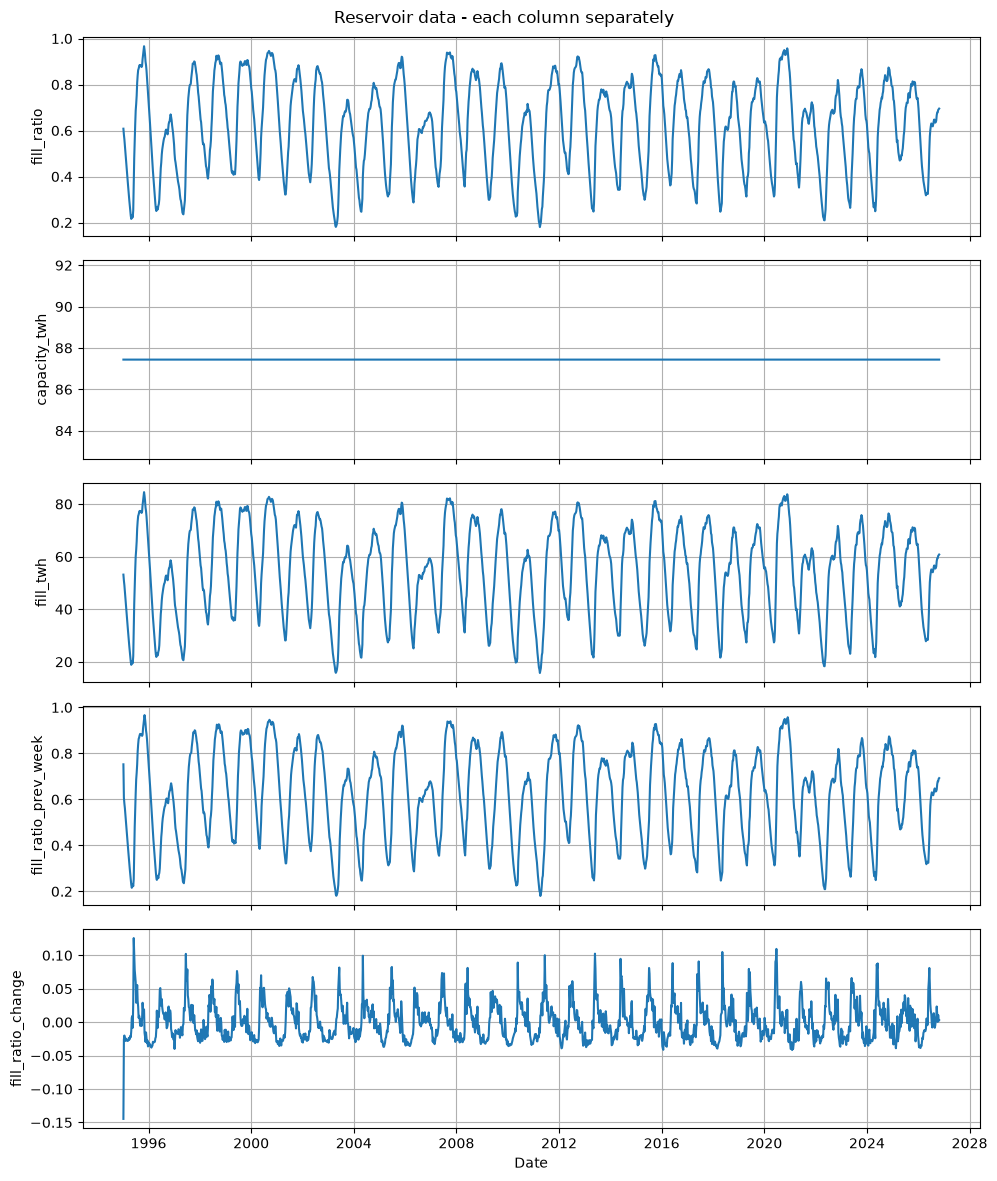

In [9]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(len(df.columns), 1, figsize=(10, 12), sharex=True)

for ax, col in zip(axes, df.columns):
    ax.plot(df.index, df[col])
    ax.set_ylabel(col)
    ax.grid(True)

axes[-1].set_xlabel("Date")
fig.suptitle("Reservoir data - each column separately")
plt.tight_layout()
plt.show()

## Plotting all columns together

Since the columns have very different scales (e.g. `capacity_twh` is around 87, while `fill_ratio_change` is close to 0), each column is normalized to the same 0-1 scale before being shown in the same graph. This makes it possible to compare the patterns over time, even though the actual values differ greatly.

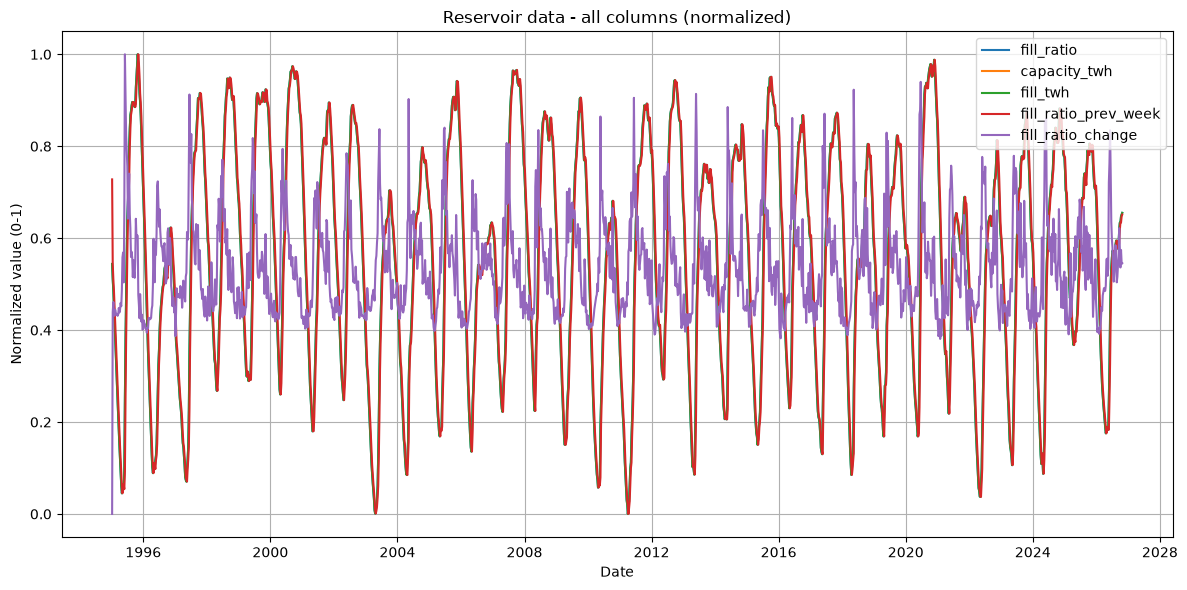

In [10]:
# Normalize each column to a 0-1 scale so they can be compared
# despite having very different units and value ranges
df_normalized = (df - df.min()) / (df.max() - df.min())

fig, ax = plt.subplots(figsize=(12, 6))
for col in df_normalized.columns:
    ax.plot(df_normalized.index, df_normalized[col], label=col)

ax.set_xlabel("Date")
ax.set_ylabel("Normalized value (0-1)")
ax.set_title("Reservoir data - all columns (normalized)")
ax.legend()
ax.grid(True)
plt.tight_layout()
plt.show()

## Spark and Cassandra connection
A local Spark session is started with the Cassandra connector. The test reads the
table `ind320.test`, which holds one row written with cqlsh and one written from Spark.

In [11]:
from pyspark.sql import SparkSession

# Local Spark session with the Cassandra connector loaded from Maven
spark = (SparkSession.builder
    .appName("ind320-part2")
    .master("local[*]")
    .config("spark.jars.packages", "com.datastax.spark:spark-cassandra-connector_2.12:3.5.1")
    .config("spark.cassandra.connection.host", "127.0.0.1")
    .config("spark.cassandra.connection.port", "9042")
    .getOrCreate())

CASS_FORMAT = "org.apache.spark.sql.cassandra"

# Read the test table back to confirm that the Spark-Cassandra connection works
test_df = (spark.read.format(CASS_FORMAT)
           .options(table="test", keyspace="ind320")
           .load())
test_df.show()

26/11/01 03:05:16 WARN Utils: Your hostname, MSI resolves to a loopback address: 127.0.1.1; using 10.255.255.254 instead (on interface lo)
26/11/01 03:05:16 WARN Utils: Set SPARK_LOCAL_IP if you need to bind to another address


:: loading settings :: url = jar:file:/home/yamama/spark-env/lib/python3.11/site-packages/pyspark/jars/ivy-2.5.3.jar!/org/apache/ivy/core/settings/ivysettings.xml


Ivy Default Cache set to: /home/yamama/.ivy2/cache
The jars for the packages stored in: /home/yamama/.ivy2/jars
com.datastax.spark#spark-cassandra-connector_2.12 added as a dependency
:: resolving dependencies :: org.apache.spark#spark-submit-parent-c08744db-dfdd-4ee4-a03b-bc03fff7ba4a;1.0
	confs: [default]
	found com.datastax.spark#spark-cassandra-connector_2.12;3.5.1 in central
	found com.datastax.spark#spark-cassandra-connector-driver_2.12;3.5.1 in central
	found org.scala-lang.modules#scala-collection-compat_2.12;2.11.0 in central
	found org.apache.cassandra#java-driver-core-shaded;4.18.1 in central
	found com.datastax.oss#native-protocol;1.5.1 in central
	found com.datastax.oss#java-driver-shaded-guava;25.1-jre-graal-sub-1 in central
	found com.typesafe#config;1.4.1 in central
	found org.slf4j#slf4j-api;1.7.26 in central
	found io.dropwizard.metrics#metrics-core;4.1.18 in central
	found org.hdrhistogram#HdrHistogram;2.1.12 in central
	found org.reactivestreams#reactive-streams;1.0

+---+----------------+
| id|            name|
+---+----------------+
|  1|hello from cqlsh|
|  2|hello from spark|
+---+----------------+



## ENTSO-E: cross-border physical flows for Norway
Hourly physical flows (MW) in both directions for connections between Norwegian
bidding zones and neighbouring zones, from November 2024 to October 2026.

In [12]:
import time
import tomllib
from pathlib import Path
import pandas as pd
from entsoe import EntsoePandasClient
from entsoe.exceptions import NoMatchingDataError

# Read the token from the local secrets file (never committed to GitHub)
with open("../.streamlit/secrets.toml", "rb") as f:
    secrets = tomllib.load(f)

# timeout stops a hanging request, retry_count retries failed ones
client_entsoe = EntsoePandasClient(
    api_key=secrets["entsoe"]["token"], retry_count=3, retry_delay=5, timeout=60)

# Connections between Norwegian bidding zones and neighbouring zones.
# Both directions are fetched for each pair.
CONNECTIONS = [
    ("NO_2", "DK_1"), ("NO_2", "DE_LU"), ("NO_2", "NL"), ("NO_2", "GB"),
    ("NO_1", "SE_3"), ("NO_3", "SE_2"), ("NO_4", "SE_1"), ("NO_4", "FI"),
]
start = pd.Timestamp("2024-11-01", tz="UTC")
end = pd.Timestamp("2026-10-31", tz="UTC")

# Every finished connection is saved here, so a rerun skips what is already fetched
cache_dir = Path("entsoe_cache")
cache_dir.mkdir(exist_ok=True)

frames = []
for a, b in CONNECTIONS:
    for src, dst in [(a, b), (b, a)]:
        cache_file = cache_dir / f"{src}_{dst}.csv"
        if cache_file.exists():
            frames.append(pd.read_csv(cache_file, parse_dates=["ts"]))
            print(f"{src} -> {dst}: loaded from cache", flush=True)
            continue

        t0 = time.time()
        try:
            s = client_entsoe.query_crossborder_flows(src, dst, start=start, end=end)
        except NoMatchingDataError:
            print(f"No data: {src} -> {dst}", flush=True)
            continue
        except Exception as e:
            print(f"FAILED {src} -> {dst}: {type(e).__name__}", flush=True)
            continue

        # Some borders report in 15-minute steps, so we average to hourly values in UTC
        s = s.tz_convert("UTC").resample("h").mean()
        part = pd.DataFrame({"ts": s.index, "from_zone": src,
                             "to_zone": dst, "flow_mw": s.values})
        part.to_csv(cache_file, index=False)
        frames.append(part)
        print(f"{src} -> {dst}: {len(part)} hours in {round(time.time() - t0)} s", flush=True)

flows = pd.concat(frames, ignore_index=True)
print(flows.shape)
flows.head()

NO_2 -> DK_1: loaded from cache
DK_1 -> NO_2: loaded from cache
NO_2 -> DE_LU: loaded from cache
DE_LU -> NO_2: loaded from cache
NO_2 -> NL: loaded from cache
NL -> NO_2: loaded from cache
NO_2 -> GB: loaded from cache
GB -> NO_2: loaded from cache
NO_1 -> SE_3: loaded from cache
SE_3 -> NO_1: loaded from cache
NO_3 -> SE_2: loaded from cache
SE_2 -> NO_3: loaded from cache
NO_4 -> SE_1: loaded from cache
SE_1 -> NO_4: loaded from cache
NO_4 -> FI: loaded from cache
FI -> NO_4: loaded from cache
(279936, 4)


,ts,from_zone,to_zone,flow_mw
0,2024-11-01 00:00:00+00:00,NO_2,DK_1,43.63
1,2024-11-01 01:00:00+00:00,NO_2,DK_1,301.49
2,2024-11-01 02:00:00+00:00,NO_2,DK_1,317.90
3,2024-11-01 03:00:00+00:00,NO_2,DK_1,447.54
4,2024-11-01 04:00:00+00:00,NO_2,DK_1,96.26


In [13]:
# Data quality check before storing the data
print("Missing values per column:")
print(flows.isna().sum())

print("\nMissing hours per connection:")
print(flows[flows["flow_mw"].isna()].groupby(["from_zone", "to_zone"]).size())

print("\nFlow summary (MW):")
print(flows["flow_mw"].describe())
print("\nTime range:", flows["ts"].min(), "to", flows["ts"].max())

Missing values per column:
ts           0
from_zone    0
to_zone      0
flow_mw      0
dtype: int64

Missing hours per connection:
Series([], dtype: int64)

Flow summary (MW):
count    279936.000000
mean        301.914699
std         485.512873
min           0.000000
25%           0.000000
50%           0.198866
75%         446.346916
max        2299.567500
Name: flow_mw, dtype: float64

Time range: 2024-11-01 00:00:00+00:00 to 2026-10-30 23:00:00+00:00


## Storing the flows in Cassandra with Spark
The hourly flows are written to the table `ind320.entsoe_flows` through the Spark-Cassandra connector.

In [14]:
from pyspark.sql import functions as F

# Show Spark timestamps in UTC
spark.conf.set("spark.sql.session.timeZone", "UTC")

# Send timestamps as epoch seconds (independent of the local time zone of Python)
# and let Spark convert them to timestamps. This avoids the 1-2 hour shift
# and the lost hours at the daylight saving transition.
flows_to_write = flows.copy()
flows_to_write["ts_epoch"] = (
    (flows_to_write["ts"] - pd.Timestamp("1970-01-01", tz="UTC"))
    // pd.Timedelta(seconds=1)
)

sdf = (spark.createDataFrame(
           flows_to_write[["from_zone", "to_zone", "ts_epoch", "flow_mw"]])
       .withColumn("ts", F.timestamp_seconds("ts_epoch"))
       .select("from_zone", "to_zone", "ts", "flow_mw"))

(sdf.write.format(CASS_FORMAT)
    .options(table="entsoe_flows", keyspace="ind320")
    .mode("append")
    .save())

# Read back and check: row count and the first timestamps for one connection
check_df = (spark.read.format(CASS_FORMAT)
            .options(table="entsoe_flows", keyspace="ind320").load())
print("Rows in Cassandra:", check_df.count())
(check_df.filter("from_zone = 'NO_2' AND to_zone = 'DK_1'")
 .orderBy("ts").limit(3).show(truncate=False))

Rows in Cassandra: 279936
+---------+-------+-------------------+-------+
|from_zone|to_zone|ts                 |flow_mw|
+---------+-------+-------------------+-------+
|NO_2     |DK_1   |2024-11-01 00:00:00|43.63  |
|NO_2     |DK_1   |2024-11-01 01:00:00|301.49 |
|NO_2     |DK_1   |2024-11-01 02:00:00|317.9  |
+---------+-------+-------------------+-------+



## Extracting data with Spark and the pie chart
Spark reads the flows from Cassandra, adds year and month columns and sums the
energy per connection, direction and year. The pie chart shows one connection
for 2025, split into energy out of and into Norway.

In [15]:
from pyspark.sql import functions as F

# Use Spark to extract the relevant columns from Cassandra and add year and month
extracted = (spark.read.format(CASS_FORMAT)
             .options(table="entsoe_flows", keyspace="ind320").load()
             .select("from_zone", "to_zone", "ts", "flow_mw")
             .withColumn("year", F.year("ts"))
             .withColumn("month", F.month("ts")))

# Spark aggregation: total energy per connection, direction and year
# (hourly values in MW summed over hours give MWh)
yearly = (extracted.groupBy("from_zone", "to_zone", "year")
          .agg(F.sum("flow_mw").alias("total_mwh"))
          .orderBy("from_zone", "to_zone", "year"))
yearly.show(10)

+---------+-------+----+------------------+
|from_zone|to_zone|year|         total_mwh|
+---------+-------+----+------------------+
|    DE_LU|   NO_2|2024| 66345.17749999998|
|    DE_LU|   NO_2|2025| 766714.5682499985|
|    DE_LU|   NO_2|2026|2339632.8032499943|
|     DK_1|   NO_2|2024|133711.56000000003|
|     DK_1|   NO_2|2025|1153573.2177235007|
|     DK_1|   NO_2|2026| 2772586.585844502|
|       FI|   NO_4|2024| 9147.445000000003|
|       FI|   NO_4|2025| 47298.16618374985|
|       FI|   NO_4|2026|30385.217391000006|
|       GB|   NO_2|2024|13907.610000000004|
+---------+-------+----+------------------+
only showing top 10 rows



In [16]:
# Sanity check: hours and total energy per month for one connection
chk = (extracted.filter("from_zone = 'DE_LU' AND to_zone = 'NO_2'")
       .groupBy("year", "month")
       .agg(F.count("*").alias("hours"),
            F.round(F.sum("flow_mw")).alias("total_mwh"))
       .orderBy("year", "month"))
chk.show(30)

+----+-----+-----+---------+
|year|month|hours|total_mwh|
+----+-----+-----+---------+
|2024|   11|  720|  40778.0|
|2024|   12|  744|  25567.0|
|2025|    1|  744|  51309.0|
|2025|    2|  672|   2602.0|
|2025|    3|  744|  32932.0|
|2025|    4|  720|  91914.0|
|2025|    5|  744| 165074.0|
|2025|    6|  720| 163557.0|
|2025|    7|  744|  53483.0|
|2025|    8|  744| 114127.0|
|2025|    9|  720|  32174.0|
|2025|   10|  744|  51975.0|
|2025|   11|  720|   3903.0|
|2025|   12|  744|   3663.0|
|2026|    1|  744|  68405.0|
|2026|    2|  672| 282798.0|
|2026|    3|  744| 298185.0|
|2026|    4|  720| 335293.0|
|2026|    5|  744| 257778.0|
|2026|    6|  720| 209042.0|
|2026|    7|  744| 258586.0|
|2026|    8|  744| 239247.0|
|2026|    9|  720| 204221.0|
|2026|   10|  720| 186077.0|
+----+-----+-----+---------+



In [17]:
# Check 1: both directions of NO_2 <-> DE_LU per month
both = (extracted.filter(
            ((F.col("from_zone") == "DE_LU") & (F.col("to_zone") == "NO_2")) |
            ((F.col("from_zone") == "NO_2") & (F.col("to_zone") == "DE_LU")))
        .withColumn("direction", F.concat_ws(" -> ", "from_zone", "to_zone"))
        .groupBy("year", "month")
        .pivot("direction")
        .agg(F.round(F.sum("flow_mw")))
        .orderBy("year", "month"))
both.show(30)

# Check 2: highest hourly flow per direction and year (NordLink capacity is 1400 MW)
(extracted.filter(
    ((F.col("from_zone") == "DE_LU") & (F.col("to_zone") == "NO_2")) |
    ((F.col("from_zone") == "NO_2") & (F.col("to_zone") == "DE_LU")))
 .groupBy("from_zone", "to_zone", "year")
 .agg(F.round(F.max("flow_mw")).alias("max_hourly_mw"))
 .orderBy("from_zone", "year")
 .show())

+----+-----+-------------+-------------+
|year|month|DE_LU -> NO_2|NO_2 -> DE_LU|
+----+-----+-------------+-------------+
|2024|   11|      40778.0|     629149.0|
|2024|   12|      25567.0|     657330.0|
|2025|    1|      51309.0|     702804.0|
|2025|    2|       2602.0|     809403.0|
|2025|    3|      32932.0|     589635.0|
|2025|    4|      91914.0|     573609.0|
|2025|    5|     165074.0|     533765.0|
|2025|    6|     163557.0|     432639.0|
|2025|    7|      53483.0|     609056.0|
|2025|    8|     114127.0|     527274.0|
|2025|    9|      32174.0|     631498.0|
|2025|   10|      51975.0|     727431.0|
|2025|   11|       3903.0|     812228.0|
|2025|   12|       3663.0|     838514.0|
|2026|    1|      68405.0|     653259.0|
|2026|    2|     282798.0|     199748.0|
|2026|    3|     298185.0|     423240.0|
|2026|    4|     335293.0|     342400.0|
|2026|    5|     257778.0|     465616.0|
|2026|    6|     209042.0|     503131.0|
|2026|    7|     258586.0|     481053.0|
|2026|    8|    

+---------+-------+----+-------------+
|from_zone|to_zone|year|max_hourly_mw|
+---------+-------+----+-------------+
|    DE_LU|   NO_2|2024|       1401.0|
|    DE_LU|   NO_2|2025|       1402.0|
|    DE_LU|   NO_2|2026|       1444.0|
|     NO_2|  DE_LU|2024|       1405.0|
|     NO_2|  DE_LU|2025|       1407.0|
|     NO_2|  DE_LU|2026|       1406.0|
+---------+-------+----+-------------+



## Line plot: first month of a year
Hourly flows for January 2025, one line per connection and direction. The upper
panel shows flows out of Norway, the lower panel flows into Norway.

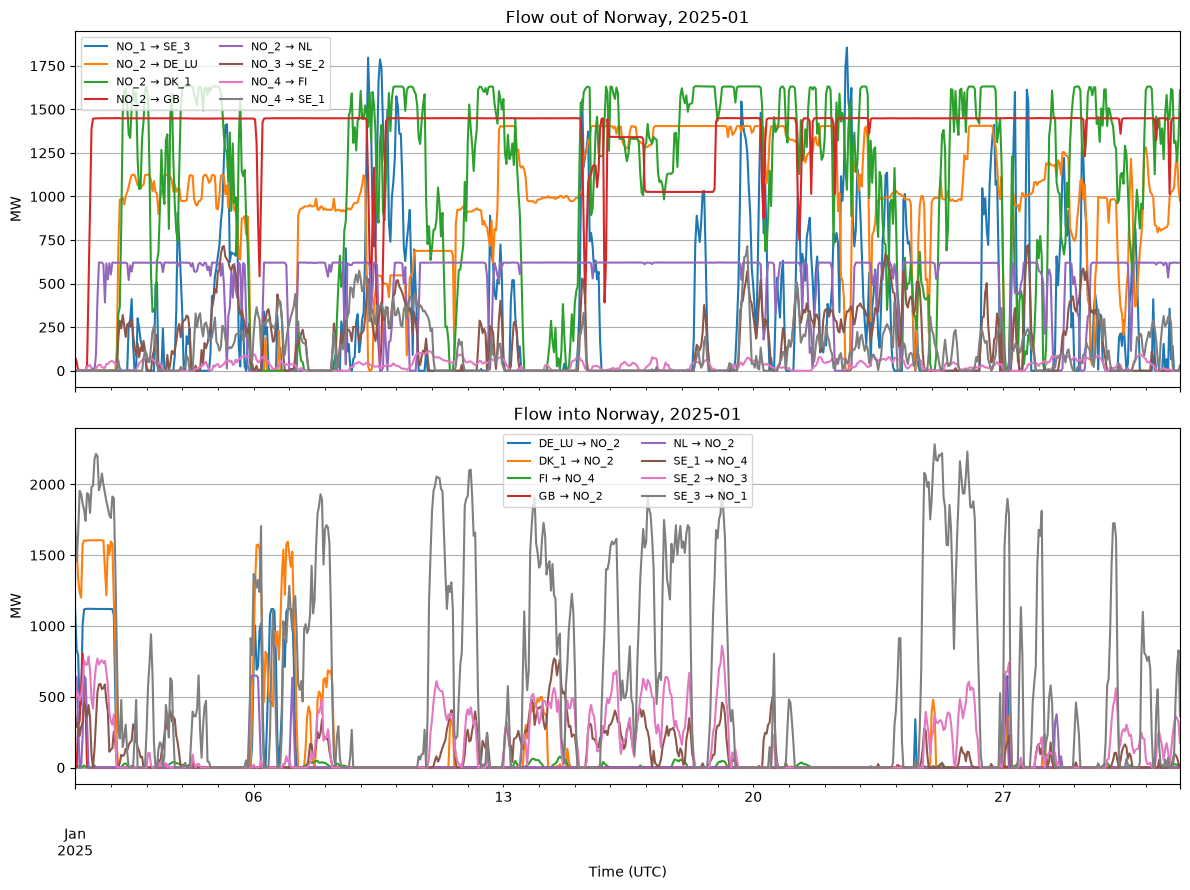

In [18]:
import matplotlib.pyplot as plt
import pandas as pd
from pyspark.sql import functions as F

# Make Spark format timestamps in UTC (the ENTSO-E data is in UTC)
spark.conf.set("spark.sql.session.timeZone", "UTC")

# First month of the chosen year (2025 is a full calendar year in the data)
year, month = 2025, 1

# Spark extracts the month. The timestamp is sent to pandas as text, because
# converting Spark timestamps directly fails with this pyspark/pandas combination.
jan = (extracted.filter((F.col("year") == year) & (F.col("month") == month))
       .select("from_zone", "to_zone",
               F.date_format("ts", "yyyy-MM-dd HH:mm:ss").alias("ts"),
               "flow_mw")
       .toPandas())
jan["ts"] = pd.to_datetime(jan["ts"], utc=True)
jan["connection"] = jan["from_zone"] + " → " + jan["to_zone"]

# One column per connection and direction.
# pivot_table averages if two rows share the same timestamp (pivot would fail).
wide = jan.pivot_table(index="ts", columns="connection",
                       values="flow_mw", aggfunc="mean")

# Split into flows out of Norway (from a NO zone) and into Norway
out_cols = [c for c in wide.columns if c.startswith("NO")]
in_cols = [c for c in wide.columns if not c.startswith("NO")]

fig, axes = plt.subplots(2, 1, figsize=(12, 9), sharex=True)
wide[out_cols].plot(ax=axes[0])
axes[0].set_title(f"Flow out of Norway, {year}-{month:02d}")
wide[in_cols].plot(ax=axes[1])
axes[1].set_title(f"Flow into Norway, {year}-{month:02d}")
for ax in axes:
    ax.set_ylabel("MW")
    ax.grid(True)
    ax.legend(fontsize=8, ncol=2)
axes[1].set_xlabel("Time (UTC)")
plt.tight_layout()
plt.show()

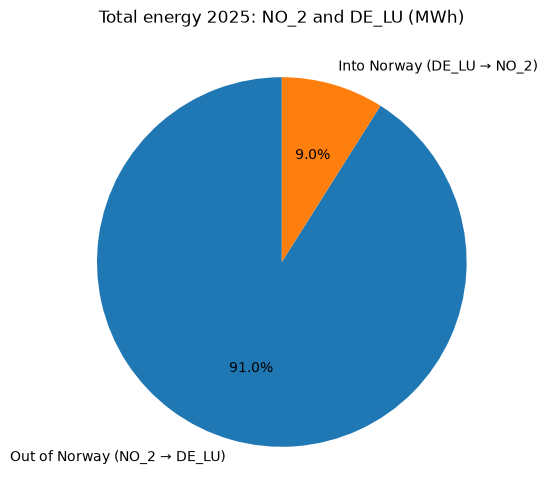

In [19]:
import matplotlib.pyplot as plt
from pyspark.sql import functions as F

# Chosen connection and year for the pie chart
zone_a, zone_b, pie_year = "NO_2", "DE_LU", 2025

# Spark: total energy per direction for the chosen connection and year
# (requires the Spark session `spark` and CASS_FORMAT from the Spark cell above)
pie_df = (spark.read.format(CASS_FORMAT)
          .options(table="entsoe_flows", keyspace="ind320").load()
          .withColumn("year", F.year("ts"))
          .filter(F.col("year") == pie_year)
          .filter(((F.col("from_zone") == zone_a) & (F.col("to_zone") == zone_b)) |
                  ((F.col("from_zone") == zone_b) & (F.col("to_zone") == zone_a)))
          .groupBy("from_zone", "to_zone")
          .agg(F.sum("flow_mw").alias("total_mwh"))
          .toPandas())

# Energy out of Norway (from the NO zone) and into Norway (to the NO zone)
out_mwh = pie_df.loc[pie_df["from_zone"] == zone_a, "total_mwh"].sum()
in_mwh = pie_df.loc[pie_df["from_zone"] == zone_b, "total_mwh"].sum()

plt.figure(figsize=(6, 6))
plt.pie(
    [out_mwh, in_mwh],
    labels=[f"Out of Norway ({zone_a} → {zone_b})",
            f"Into Norway ({zone_b} → {zone_a})"],
    autopct="%1.1f%%",
    startangle=90,
)
plt.title(f"Total energy {pie_year}: {zone_a} and {zone_b} (MWh)")
plt.show()

In [20]:
# --- Store the Spark-extracted ENTSO-E data in MongoDB ---------------------
import pandas as pd
from pathlib import Path
from pymongo import MongoClient
from pyspark.sql import functions as F

# Hourly averages keep the collection small enough for the free Atlas tier
hourly = (extracted
          .withColumn("ts_hour", F.date_trunc("hour", "ts"))
          .groupBy("from_zone", "to_zone", "ts_hour")
          .agg(F.avg("flow_mw").alias("flow_mw"))
          .select("from_zone", "to_zone",
                  F.date_format("ts_hour", "yyyy-MM-dd HH:mm:ss").alias("ts"),
                  "flow_mw"))

# Timestamps go to pandas as text (see the toPandas problem above)
pdf = hourly.toPandas()
pdf["ts"] = pd.to_datetime(pdf["ts"], utc=True)
pdf["connection"] = pdf["from_zone"] + "-" + pdf["to_zone"]
pdf["year"] = pdf["ts"].dt.year
pdf["month"] = pdf["ts"].dt.month
print("Rows to store:", len(pdf))

# Read the MongoDB connection string from the local secrets file (not in Git)
candidates = [Path(".streamlit/secrets.toml"), Path("../.streamlit/secrets.toml")]
secrets_path = next(p for p in candidates if p.exists())
uri = None
for line in secrets_path.read_text(encoding="utf-8").splitlines():
    if line.strip().startswith("uri"):
        uri = line.split('"')[1]

client = MongoClient(uri, serverSelectionTimeoutMS=10000)
collection = client["ind320"]["entsoe_flows"]

# Replace old content so the cell can be re-run safely
collection.delete_many({})
records = pdf.to_dict("records")
for r in records:
    r["ts"] = r["ts"].to_pydatetime()

# Insert in batches of 10,000 documents
for i in range(0, len(records), 10_000):
    collection.insert_many(records[i:i + 10_000])

print("Documents in MongoDB:", collection.count_documents({}))
client.close()

Rows to store: 279936
Documents in MongoDB: 279936


## Log

In this part I replaced the CSV file from part 1 with a direct connection to the NVE Magasinstatistikk API. The notebook downloads the full weekly history with requests, converts the date column explicitly (the API returns dates as text, which I remembered from part 1), filters the national level and renames the columns to English. The two plots from part 1 are recreated from the API data. The area lookup showed that the data covers the national level (NO), five price areas (EL) and watercourse areas (VASS). VASS4 is listed in the lookup but has no data.

I set up a MongoDB Atlas account and tested the connection with pymongo. My first attempts failed because a placeholder was left in the connection string, and later because of an authentication error, which I solved by resetting the database user password. The connection string is read from a local secrets file that is not committed to GitHub, and the same value is stored in the Streamlit Cloud secrets.

For the ENTSO-E part I used the entsoe-py package to retrieve hourly physical cross-border flows for eight connections between Norwegian bidding zones and neighbouring zones, in both directions, for about two years. Some borders report in 15-minute steps, so I averaged to hourly values in UTC. Each finished connection is cached as a CSV file, so a rerun does not repeat the slow API calls. A data quality check counts missing values per connection.

Spark with the Cassandra connector writes the flows to the table ind320.entsoe_flows. My first version shifted the timestamps by one or two hours and lost hours at the daylight saving change, because of the local time zone. I fixed this by sending timestamps as epoch seconds and letting Spark convert them to UTC. Spark then extracts the columns from Cassandra, adds year and month, and sums the energy per connection, direction and year. From this I made a pie chart for one connection and year (energy out of and into Norway) and a line plot for January 2025 with one line per connection and direction. Converting Spark timestamps directly to pandas failed, so they are sent as text and converted back. The hourly Spark-extracted data was inserted into MongoDB.

In the Streamlit app, the table and plot pages fetch data from the NVE API (cached with st.cache_data). Radio buttons choose the area type (NO, EL, VASS), so the table shows one row per area with a LineChartColumn and the plot shows one line per area. The slider selects the time period that is shown. It filters the displayed data and does not control the download, because I download the full history once and cache it. The new ENTSO-E page reads from MongoDB and is split into two columns with st.columns. The left column has radio buttons for the connection, a control for the year and the pie chart. The right column has pills for choosing months and the line plot. An expander below documents the data source. All work was done on the separate branch part2.

## Use of AI

Claude (Anthropic) was used throughout the project to help with Python code (Pandas, Plotly, Streamlit, Spark), debugging errors (MongoDB authentication, Git and terminal problems, Spark and timestamp issues), explaining Git commands, and structuring the log and screencast.
